La question qu'on va se poser

Est-ce que les stations du cluster "problématique" (cluster 1) sont aussi celles que la régression prédit mal ?

Si oui → les deux modèles convergent et se renforcent mutuellement.
Si non → tu as deux signaux indépendants complémentaires.

1. Recharger le modèle RF (régression DBO5)
2. Calculer l'erreur de prédiction par station (résidu absolu)
3. Joindre avec les clusters
4. Comparer l'erreur moyenne par cluster
5. Visualiser : boxplot des erreurs par cluster
6. Conclusion narrative

 # Imports & chargement

In [38]:
from pyspark.sql.session import SparkSession
import pyspark.sql.functions as sf
from pyspark.ml.regression import RandomForestRegressor
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler
from pyspark.ml.pipeline import Pipeline
import pandas as pd
import matplotlib.pyplot as plt

spark = SparkSession.builder.appName('Synthese').getOrCreate()
CHEMIN_INTERIM = '../data/interim'
B, BE = '\033[1m', '\033[0m'

# Charger les 2 sorties précédentes
df_LabelConf = spark.read.parquet(CHEMIN_INTERIM + '/df_LabelConf.parquet')
df_Clusters  = spark.read.parquet(CHEMIN_INTERIM + '/df_Clusters.parquet')   # cluster_KM par station

print(f'{df_LabelConf.count():,} prélèvements')
print(f'{df_Clusters.count():,} stations clustérisées')

92,840 prélèvements
1,874 stations clustérisées


# Réentraîner RF + calculer les résidus

In [40]:
# Mêmes étapes que ton notebook 05 — pipeline encodage + features
df_PreReg = (df_LabelConf
    .select('CdSta', 'CatSta', 'NoDep', 'MoPrel', 'AnPrel',
            'A3_DBO5', 'A3_DCO', 'A3_MES', 'CapNomSta', 'Rdt_DBO5')
    .filter(sf.col('Rdt_DBO5').isNotNull()
            & sf.col('A3_DBO5').isNotNull()
            & sf.col('A3_DCO').isNotNull()
            & sf.col('A3_MES').isNotNull()
            & sf.col('CapNomSta').isNotNull())
)

col_idx = ['AnPrel', 'MoPrel', 'NoDep', 'CatSta']
indexeur = [StringIndexer(inputCol=c, outputCol=c+'_idx', handleInvalid='keep') for c in col_idx]
encodeur = [OneHotEncoder(inputCol=c+'_idx', outputCol=c+'_ohe', handleInvalid='keep') for c in col_idx]
assembleur = VectorAssembler(
    inputCols=['AnPrel_ohe', 'MoPrel_ohe', 'NoDep_ohe', 'CatSta_ohe',
               'CapNomSta', 'A3_DBO5', 'A3_DCO', 'A3_MES'],
    outputCol='features'
)
df_Reg = Pipeline(stages=[*indexeur, *encodeur, assembleur]).fit(df_PreReg).transform(df_PreReg)

# Entraîner RF avec les meilleurs hyperparams trouvés
rf = RandomForestRegressor(featuresCol='features', labelCol='Rdt_DBO5', 
                           numTrees=50, maxDepth=10, seed=2026)
rf_model = rf.fit(df_Reg)
df_pred = rf_model.transform(df_Reg)

# Calcul du résidu absolu (erreur en valeur absolue)
df_pred = df_pred.withColumn('erreur_abs', sf.abs(sf.col('Rdt_DBO5') - sf.col('prediction')))
df_pred.select('CdSta', 'Rdt_DBO5', 'prediction', 'erreur_abs').show(5)

+------------+-----------------+-----------------+-------------------+
|       CdSta|         Rdt_DBO5|       prediction|         erreur_abs|
+------------+-----------------+-----------------+-------------------+
|030201101000|95.45454545454545|92.85938227643388| 2.5951631781115765|
|030201802000|95.52238805970148|94.78587062178175| 0.7365174379197299|
|030203601000| 99.0909090909091| 98.7233810796526|0.36752801125649626|
|030203702000|96.66666666666667| 97.6228316706191| 0.9561650039524352|
|030204601000|96.81818181818181|97.92236635664834| 1.1041845384665265|
+------------+-----------------+-----------------+-------------------+
only showing top 5 rows


# Erreur moyenne par station, puis jointure cluster

In [42]:
# Erreur moyenne par station (1 ligne = 1 station)
df_ErrPar = (
    df_pred.groupBy('CdSta')
    .agg(
        sf.round(sf.avg('erreur_abs'), 2).alias('Erreur_moy'),
        sf.round(sf.stddev('erreur_abs'), 2).alias('Erreur_std'),
        sf.count('*').alias('NbPrelevements'),
    )
)

# Jointure avec les clusters
df_Synthese = df_ErrPar.join(df_Clusters, on='CdSta', how='inner')

print(f'{df_Synthese.count():,} stations avec erreur + cluster')
df_Synthese.show(5)

1,874 stations avec erreur + cluster
+------------+----------+----------+--------------+----------+
|       CdSta|Erreur_moy|Erreur_std|NbPrelevements|cluster_KM|
+------------+----------+----------+--------------+----------+
|031402201000|      1.92|      3.07|            59|         0|
|032711601000|      1.36|      2.39|            60|         0|
|036057702000|      0.57|      0.82|            60|         0|
|037621901000|      1.61|      3.08|            61|         0|
|037653501000|      1.42|      0.91|            59|         0|
+------------+----------+----------+--------------+----------+
only showing top 5 rows


# Comparaison des erreurs par cluster

In [44]:
df_Synthese.groupBy('cluster_KM').agg(
    sf.count('*').alias('NbStations'),
    sf.round(sf.avg('Erreur_moy'), 2).alias('Erreur_moyenne'),
    sf.round(sf.stddev('Erreur_moy'), 2).alias('Erreur_ecart_type'),
    sf.round(sf.expr('percentile_approx(Erreur_moy, 0.5)'), 2).alias('Erreur_mediane'),
    sf.round(sf.max('Erreur_moy'), 2).alias('Erreur_max'),
).orderBy('cluster_KM').show()

+----------+----------+--------------+-----------------+--------------+----------+
|cluster_KM|NbStations|Erreur_moyenne|Erreur_ecart_type|Erreur_mediane|Erreur_max|
+----------+----------+--------------+-----------------+--------------+----------+
|         0|      1713|           2.0|             1.86|          1.49|     24.05|
|         1|       160|         13.14|             8.63|         11.78|     46.97|
|         2|         1|           1.9|             NULL|           1.9|       1.9|
+----------+----------+--------------+-----------------+--------------+----------+



# Visualisation : boxplot des erreurs par cluster

<Figure size 800x500 with 0 Axes>

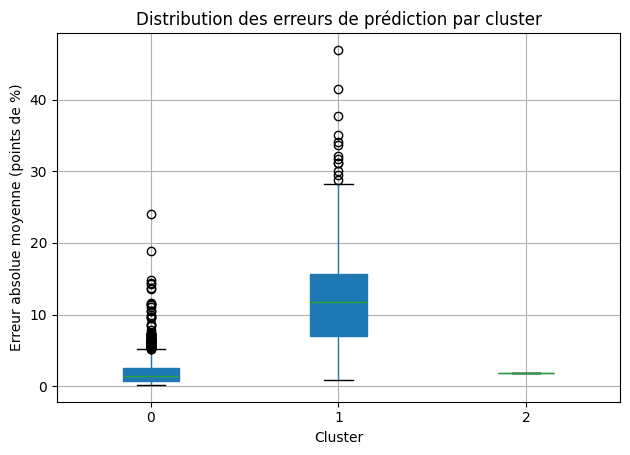

In [46]:
df_Syn_pd = df_Synthese.select('cluster_KM', 'Erreur_moy').toPandas()

plt.figure(figsize=(8, 5))
df_Syn_pd.boxplot(column='Erreur_moy', by='cluster_KM', grid=True, patch_artist=True)
plt.xlabel('Cluster')
plt.ylabel('Erreur absolue moyenne (points de %)')
plt.title('Distribution des erreurs de prédiction par cluster')
plt.suptitle('')
plt.tight_layout()
plt.savefig('../reports/figures/synthese_erreurs_par_cluster.png', dpi=150)
plt.show()